
# Gaussian Mixture Model (GMM) Analysis

## NBA Player Archetype Identification

This notebook applies Gaussian Mixture Models (GMM) to identify distinct NBA player archetypes based on standardized player statistics.

The analysis includes:
1. Data loading and inspection
2. Feature selection
3. GMM model fitting
4. Model selection using AIC and BIC
5. Cluster evaluation
6. PCA visualization
7. Player archetype interpretation


In [1]:

# 1. Import Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# Set display options
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

# Set visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# 2. Load Standardized NBA Dataset

data_path = Path("../data/processed/clustering_features_standardized.csv")

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (1979, 22)


,PLAYER_ID,PLAYER_NAME,SEASON,TEAM_ID,TEAM_ABBREVIATION,PLAYER_POSITION_defend_rim,GP_player_totals,MIN_player_totals,USG_PCT_player_advanced,AST_PCT_player_advanced,OREB_PCT_player_advanced,DREB_PCT_player_advanced,PCT_PTS_FT_player_scoring,PCT_PTS_FB_player_scoring,SHOT_SHARE_PAINT_NON_RA,SHOT_SHARE_MID_RANGE,SHOT_SHARE_CORNER_3,SHOT_SHARE_ABOVE_BREAK_3,PCT_LOOSE_BALLS_RECOVERED_DEF_hustle,PCT_BOX_OUTS_DEF_hustle,FREQ_defend_rim,SCREEN_ASSISTS_PER36
0,2544,LeBron James,2021-22,1610612747,LAL,F,56,2084.335000,2.436660,1.772005,-0.435866,1.018149,0.129093,0.561810,-1.111832,0.788489,-1.026086,0.323003,0.706144,-0.369247,0.213456,-0.207812
1,2544,LeBron James,2022-23,1610612747,LAL,F,55,1953.940000,2.528841,1.903393,-0.375396,1.135381,0.271727,1.590602,-0.492258,1.072250,-1.062786,-0.029718,0.618643,-0.576259,0.456607,-0.373665
2,2544,LeBron James,2023-24,1610612747,LAL,F,71,2503.683333,1.846697,2.500612,-0.587042,0.764145,0.432191,1.289059,-0.375199,0.507270,-0.966873,-0.230315,-0.089318,-0.203637,-0.196862,-0.447988
3,2544,LeBron James,2024-25,1610612747,LAL,F,70,2444.446667,1.957315,2.942554,-0.435866,1.057226,0.164752,1.147157,0.308845,1.078706,-1.029540,-0.033887,-0.407502,-0.272641,-0.713558,-0.300189
4,2544,LeBron James,2025-26,1610612747,LAL,F,60,1989.055000,1.422662,2.261724,-0.677748,0.529679,0.753117,2.601655,0.089208,1.078730,-0.755521,-0.483789,0.014092,0.189686,-0.576785,-0.415770


In [3]:

# 3. Initial Data Inspection

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes)

print("\nMissing values:")
display(df.isnull().sum())

print("\nSummary statistics:")
display(df.describe().T)


Number of rows: 1979
Number of columns: 22

Column names:
['PLAYER_ID', 'PLAYER_NAME', 'SEASON', 'TEAM_ID', 'TEAM_ABBREVIATION', 'PLAYER_POSITION_defend_rim', 'GP_player_totals', 'MIN_player_totals', 'USG_PCT_player_advanced', 'AST_PCT_player_advanced', 'OREB_PCT_player_advanced', 'DREB_PCT_player_advanced', 'PCT_PTS_FT_player_scoring', 'PCT_PTS_FB_player_scoring', 'SHOT_SHARE_PAINT_NON_RA', 'SHOT_SHARE_MID_RANGE', 'SHOT_SHARE_CORNER_3', 'SHOT_SHARE_ABOVE_BREAK_3', 'PCT_LOOSE_BALLS_RECOVERED_DEF_hustle', 'PCT_BOX_OUTS_DEF_hustle', 'FREQ_defend_rim', 'SCREEN_ASSISTS_PER36']

Data types:


PLAYER_ID                                 int64
PLAYER_NAME                                 str
SEASON                                      str
TEAM_ID                                   int64
TEAM_ABBREVIATION                           str
PLAYER_POSITION_defend_rim                  str
GP_player_totals                          int64
MIN_player_totals                       float64
USG_PCT_player_advanced                 float64
AST_PCT_player_advanced                 float64
OREB_PCT_player_advanced                float64
DREB_PCT_player_advanced                float64
PCT_PTS_FT_player_scoring               float64
PCT_PTS_FB_player_scoring               float64
SHOT_SHARE_PAINT_NON_RA                 float64
SHOT_SHARE_MID_RANGE                    float64
SHOT_SHARE_CORNER_3                     float64
SHOT_SHARE_ABOVE_BREAK_3                float64
PCT_LOOSE_BALLS_RECOVERED_DEF_hustle    float64
PCT_BOX_OUTS_DEF_hustle                 float64
FREQ_defend_rim                         


Missing values:


PLAYER_ID                               0
PLAYER_NAME                             0
SEASON                                  0
TEAM_ID                                 0
TEAM_ABBREVIATION                       0
PLAYER_POSITION_defend_rim              0
GP_player_totals                        0
MIN_player_totals                       0
USG_PCT_player_advanced                 0
AST_PCT_player_advanced                 0
OREB_PCT_player_advanced                0
DREB_PCT_player_advanced                0
PCT_PTS_FT_player_scoring               0
PCT_PTS_FB_player_scoring               0
SHOT_SHARE_PAINT_NON_RA                 0
SHOT_SHARE_MID_RANGE                    0
SHOT_SHARE_CORNER_3                     0
SHOT_SHARE_ABOVE_BREAK_3                0
PCT_LOOSE_BALLS_RECOVERED_DEF_hustle    0
PCT_BOX_OUTS_DEF_hustle                 0
FREQ_defend_rim                         0
SCREEN_ASSISTS_PER36                    0
dtype: int64


Summary statistics:


,count,mean,std,min,25%,50%,75%,max
PLAYER_ID,1979.0,1.318967e+06,592065.751642,2.544000e+03,1.626179e+06,1.629312e+06,1.630560e+06,1.643016e+06
TEAM_ID,1979.0,1.610613e+09,8.669791,1.610613e+09,1.610613e+09,1.610613e+09,1.610613e+09,1.610613e+09
GP_player_totals,1979.0,5.971703e+01,15.058255,1.200000e+01,5.000000e+01,6.200000e+01,7.200000e+01,8.400000e+01
MIN_player_totals,1979.0,1.437519e+03,655.749554,4.000517e+02,8.719025e+02,1.393950e+03,1.966876e+03,3.036093e+03
USG_PCT_player_advanced,1979.0,-8.616991e-17,1.000253,-2.448966e+00,-7.343880e-01,-1.812983e-01,6.114636e-01,3.727202e+00
AST_PCT_player_advanced,1979.0,2.656906e-16,1.000253,-1.524643e+00,-7.721476e-01,-2.824281e-01,5.895115e-01,3.826438e+00
OREB_PCT_player_advanced,1979.0,-3.321132e-17,1.000253,-1.252217e+00,-7.382184e-01,-3.451609e-01,4.409541e-01,4.704116e+00
DREB_PCT_player_advanced,1979.0,9.335074e-17,1.000253,-1.795434e+00,-7.403407e-01,-2.518714e-01,5.687570e-01,4.300662e+00
PCT_PTS_FT_player_scoring,1979.0,-3.231372e-16,1.000253,-2.367003e+00,-7.267112e-01,-1.354087e-02,6.639710e-01,4.069359e+00
PCT_PTS_FB_player_scoring,1979.0,1.148932e-16,1.000253,-2.240760e+00,-7.330483e-01,-4.127463e-02,5.972856e-01,4.446385e+00


In [4]:

# 4. Check Data Quality

print("Data types:")
display(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nNumber of duplicated rows:")
print(df.duplicated().sum())

print("\nNumber of unique players:")
print(df["PLAYER_ID"].nunique())

print("\nNumber of seasons:")
print(df["SEASON"].nunique())

print("\nSeason distribution:")
print(df["SEASON"].value_counts().sort_index())


Data types:


PLAYER_ID                                 int64
PLAYER_NAME                                 str
SEASON                                      str
TEAM_ID                                   int64
TEAM_ABBREVIATION                           str
PLAYER_POSITION_defend_rim                  str
GP_player_totals                          int64
MIN_player_totals                       float64
USG_PCT_player_advanced                 float64
AST_PCT_player_advanced                 float64
OREB_PCT_player_advanced                float64
DREB_PCT_player_advanced                float64
PCT_PTS_FT_player_scoring               float64
PCT_PTS_FB_player_scoring               float64
SHOT_SHARE_PAINT_NON_RA                 float64
SHOT_SHARE_MID_RANGE                    float64
SHOT_SHARE_CORNER_3                     float64
SHOT_SHARE_ABOVE_BREAK_3                float64
PCT_LOOSE_BALLS_RECOVERED_DEF_hustle    float64
PCT_BOX_OUTS_DEF_hustle                 float64
FREQ_defend_rim                         


Missing values:
PLAYER_ID                               0
PLAYER_NAME                             0
SEASON                                  0
TEAM_ID                                 0
TEAM_ABBREVIATION                       0
PLAYER_POSITION_defend_rim              0
GP_player_totals                        0
MIN_player_totals                       0
USG_PCT_player_advanced                 0
AST_PCT_player_advanced                 0
OREB_PCT_player_advanced                0
DREB_PCT_player_advanced                0
PCT_PTS_FT_player_scoring               0
PCT_PTS_FB_player_scoring               0
SHOT_SHARE_PAINT_NON_RA                 0
SHOT_SHARE_MID_RANGE                    0
SHOT_SHARE_CORNER_3                     0
SHOT_SHARE_ABOVE_BREAK_3                0
PCT_LOOSE_BALLS_RECOVERED_DEF_hustle    0
PCT_BOX_OUTS_DEF_hustle                 0
FREQ_defend_rim                         0
SCREEN_ASSISTS_PER36                    0
dtype: int64

Number of duplicated rows:
0

Number of uniqu

In [5]:

# 5. Define Candidate Clustering Features

features = [
    "USG_PCT_player_advanced",
    "AST_PCT_player_advanced",
    "OREB_PCT_player_advanced",
    "DREB_PCT_player_advanced",
    "PCT_PTS_FT_player_scoring",
    "PCT_PTS_FB_player_scoring",
    "SHOT_SHARE_PAINT_NON_RA",
    "SHOT_SHARE_MID_RANGE",
    "SHOT_SHARE_CORNER_3",
    "SHOT_SHARE_ABOVE_BREAK_3",
    "PCT_LOOSE_BALLS_RECOVERED_DEF_hustle",
    "PCT_BOX_OUTS_DEF_hustle",
    "FREQ_defend_rim",
    "SCREEN_ASSISTS_PER36"
]

# Check mean and standard deviation
feature_summary = df[features].agg(["mean", "std"]).T

display(feature_summary)


,mean,std
USG_PCT_player_advanced,-8.616991e-17,1.000253
AST_PCT_player_advanced,2.656906e-16,1.000253
OREB_PCT_player_advanced,-3.321132e-17,1.000253
DREB_PCT_player_advanced,9.335074e-17,1.000253
PCT_PTS_FT_player_scoring,-3.231372e-16,1.000253
PCT_PTS_FB_player_scoring,1.148932e-16,1.000253
SHOT_SHARE_PAINT_NON_RA,-1.615686e-16,1.000253
SHOT_SHARE_MID_RANGE,4.308496e-17,1.000253
SHOT_SHARE_CORNER_3,5.026578e-17,1.000253
SHOT_SHARE_ABOVE_BREAK_3,-5.565140e-17,1.000253


,USG_PCT_player_advanced,AST_PCT_player_advanced,OREB_PCT_player_advanced,DREB_PCT_player_advanced,PCT_PTS_FT_player_scoring,PCT_PTS_FB_player_scoring,SHOT_SHARE_PAINT_NON_RA,SHOT_SHARE_MID_RANGE,SHOT_SHARE_CORNER_3,SHOT_SHARE_ABOVE_BREAK_3,PCT_LOOSE_BALLS_RECOVERED_DEF_hustle,PCT_BOX_OUTS_DEF_hustle,FREQ_defend_rim,SCREEN_ASSISTS_PER36
USG_PCT_player_advanced,1.00,0.57,-0.24,0.10,0.41,-0.05,0.30,0.51,-0.50,0.12,-0.06,0.15,-0.06,-0.20
AST_PCT_player_advanced,0.57,1.00,-0.33,-0.09,0.24,-0.04,0.36,0.39,-0.42,0.12,0.07,0.26,-0.22,-0.26
OREB_PCT_player_advanced,-0.24,-0.33,1.00,0.70,0.19,-0.37,0.20,-0.38,-0.33,-0.69,-0.38,-0.74,0.43,0.82
DREB_PCT_player_advanced,0.10,-0.09,0.70,1.00,0.23,-0.38,0.24,-0.13,-0.41,-0.45,-0.27,-0.55,0.49,0.67
PCT_PTS_FT_player_scoring,0.41,0.24,0.19,0.23,1.00,-0.12,0.30,0.11,-0.45,-0.33,-0.19,-0.16,0.12,0.19
PCT_PTS_FB_player_scoring,-0.05,-0.04,-0.37,-0.38,-0.12,1.00,-0.20,-0.07,0.32,0.13,0.19,0.24,-0.28,-0.51
SHOT_SHARE_PAINT_NON_RA,0.30,0.36,0.20,0.24,0.30,-0.20,1.00,0.15,-0.56,-0.53,-0.19,-0.10,0.09,0.24
SHOT_SHARE_MID_RANGE,0.51,0.39,-0.38,-0.13,0.11,-0.07,0.15,1.00,-0.25,0.06,0.07,0.28,-0.09,-0.28
SHOT_SHARE_CORNER_3,-0.50,-0.42,-0.33,-0.41,-0.45,0.32,-0.56,-0.25,1.00,0.34,0.21,0.22,-0.24,-0.42
SHOT_SHARE_ABOVE_BREAK_3,0.12,0.12,-0.69,-0.45,-0.33,0.13,-0.53,0.06,0.34,1.00,0.31,0.48,-0.31,-0.57


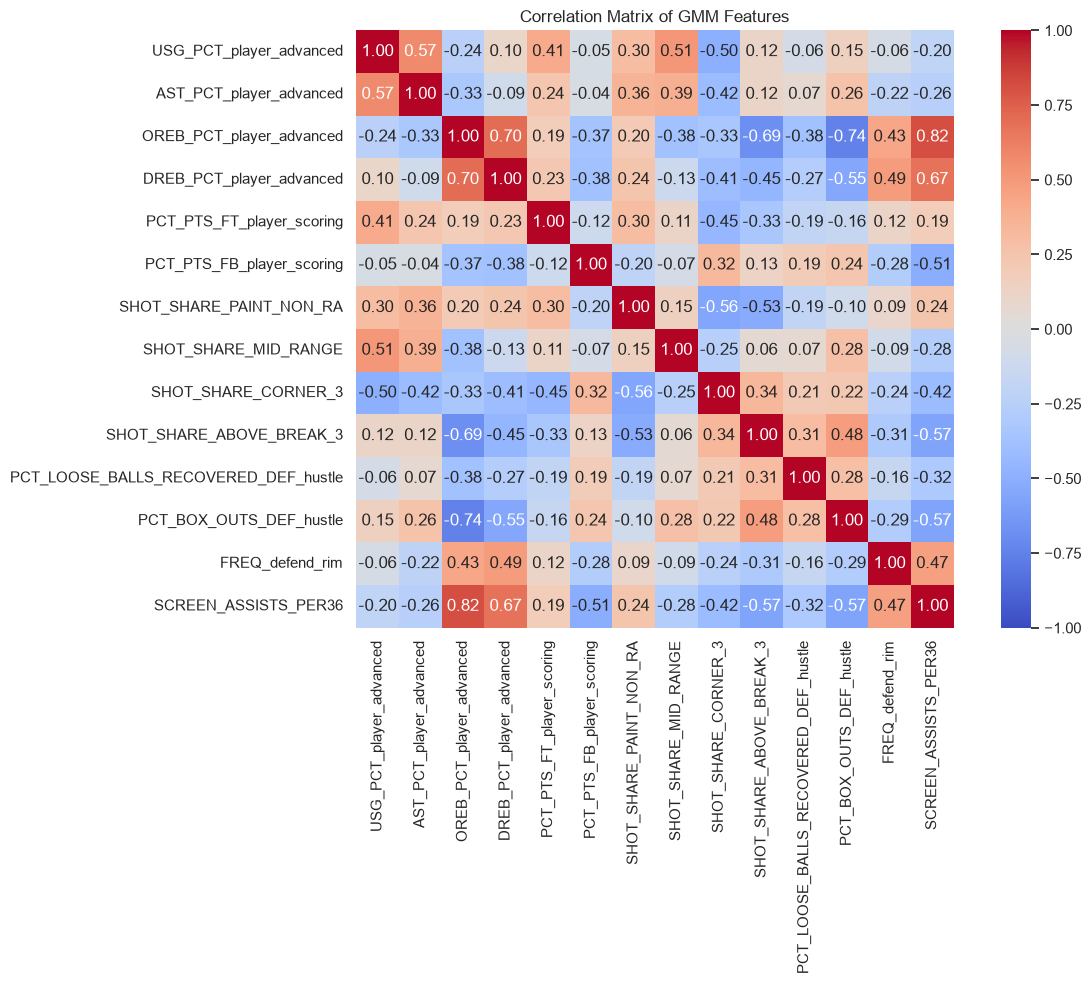

In [6]:

# 6. Feature Correlation Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlation matrix
corr_matrix = df[features].corr()

# Display correlation matrix
display(corr_matrix.round(2))

# Visualize correlation matrix
plt.figure(figsize=(13, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlation Matrix of GMM Features")
plt.tight_layout()
plt.show()


In [7]:

# 7. Identify Highly Correlated Feature Pairs

# Get upper triangle of correlation matrix
upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Find pairs with absolute correlation above 0.80
high_corr_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

high_corr_pairs["Abs Correlation"] = (
    high_corr_pairs["Correlation"].abs()
)

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["Abs Correlation"] > 0.80
].sort_values(
    "Abs Correlation",
    ascending=False
)

display(high_corr_pairs)


,Feature 1,Feature 2,Correlation,Abs Correlation
41,OREB_PCT_player_advanced,SCREEN_ASSISTS_PER36,0.820046,0.820046


## 8. Gaussian Mixture Model (GMM)

### 8.1 Data Preparation

The GMM analysis uses the 14 selected and standardized
features prepared by the data preprocessing pipeline.

In [8]:

# 8.1 Prepare data for GMM

import numpy as np
import pandas as pd

# Use the 14 standardized clustering features
X = df[features].copy()

# Check dimensions and data quality
print("Dataset shape:", X.shape)
print("Number of features:", len(features))
print("Missing values:", X.isnull().sum().sum())
print("Data type:", X.dtypes.unique())

# Convert to NumPy array for modeling
X_array = X.to_numpy(dtype=float)

print("\nGMM input is ready!")


Dataset shape: (1979, 14)
Number of features: 14
Missing values: 0
Data type: [dtype('float64')]

GMM input is ready!


### 8.2 Model Selection Using AIC and BIC

We compare different numbers of Gaussian components
and covariance structures using AIC and BIC.

In [9]:

# 8.2 Compare GMM models

from sklearn.mixture import GaussianMixture
import warnings

results = []

covariance_types = [
    "full",
    "tied",
    "diag",
    "spherical"
]

n_components_range = range(2, 11)

for covariance_type in covariance_types:

    for k in n_components_range:

        gmm = GaussianMixture(
            n_components=k,
            covariance_type=covariance_type,
            n_init=10,
            max_iter=500,
            reg_covar=1e-6,
            random_state=42
        )

        gmm.fit(X_array)

        results.append({
            "n_components": k,
            "covariance_type": covariance_type,
            "AIC": gmm.aic(X_array),
            "BIC": gmm.bic(X_array),
            "converged": gmm.converged_,
            "n_iter": gmm.n_iter_
        })

results_df = pd.DataFrame(results)

# Display models sorted by BIC
results_df = results_df.sort_values("BIC")

display(results_df.round(2))

# Best model according to BIC
best_model_result = results_df.iloc[0]

print("\nBest model according to BIC:")
print(best_model_result)


,n_components,covariance_type,AIC,BIC,converged,n_iter
4,6,full,49277.18,53296.64,True,59
5,7,full,48972.02,53662.32,True,49
6,8,full,48607.60,53968.74,True,39
7,9,full,48369.42,54401.41,True,54
8,10,full,48166.28,54869.10,True,38
26,10,diag,53801.18,55416.79,True,53
25,9,diag,54214.90,55668.39,True,42
24,8,diag,54785.67,56077.04,True,30
23,7,diag,55423.65,56552.90,True,23
3,5,full,54379.50,57728.12,True,42



Best model according to BIC:
n_components                  6
covariance_type            full
AIC                49277.175584
BIC                53296.635038
converged                  True
n_iter                       59
Name: 4, dtype: object


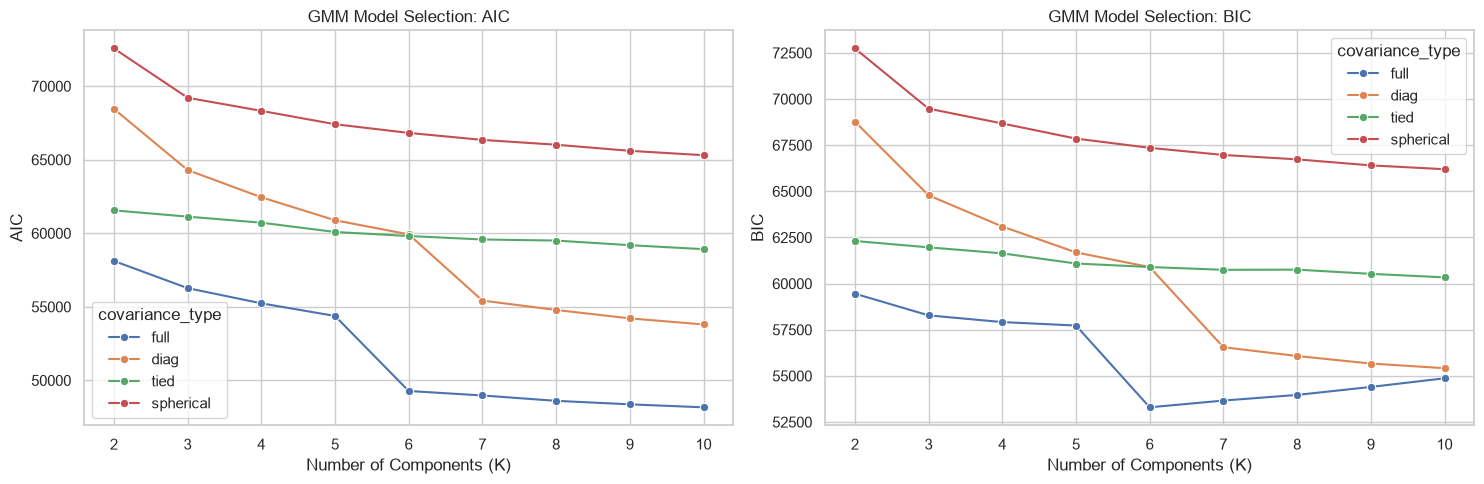

In [10]:

# 8.3 Visualize AIC and BIC

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.lineplot(
    data=results_df,
    x="n_components",
    y="AIC",
    hue="covariance_type",
    marker="o",
    ax=axes[0]
)

axes[0].set_title("GMM Model Selection: AIC")
axes[0].set_xlabel("Number of Components (K)")
axes[0].set_ylabel("AIC")

sns.lineplot(
    data=results_df,
    x="n_components",
    y="BIC",
    hue="covariance_type",
    marker="o",
    ax=axes[1]
)

axes[1].set_title("GMM Model Selection: BIC")
axes[1].set_xlabel("Number of Components (K)")
axes[1].set_ylabel("BIC")

plt.tight_layout()
plt.show()


### 8.4 Fit the Selected GMM Model

Based on BIC, we select a Gaussian Mixture Model
with 6 components and full covariance structure.

In [11]:

# 8.4 Fit the selected GMM model

from sklearn.mixture import GaussianMixture

gmm_final = GaussianMixture(
    n_components=6,
    covariance_type="full",
    n_init=20,
    max_iter=500,
    reg_covar=1e-6,
    random_state=42
)

gmm_final.fit(X_array)

# Predict cluster labels
cluster_labels = gmm_final.predict(X_array)

# Calculate posterior probabilities
posterior_probs = gmm_final.predict_proba(X_array)

print("GMM Model Results")
print("-----------------")
print("Converged:", gmm_final.converged_)
print("Iterations:", gmm_final.n_iter_)
print("AIC:", round(gmm_final.aic(X_array), 2))
print("BIC:", round(gmm_final.bic(X_array), 2))
print("Number of clusters:", gmm_final.n_components)


GMM Model Results
-----------------
Converged: True
Iterations: 59
AIC: 49277.18
BIC: 53296.64
Number of clusters: 6


,Cluster,Count,Percentage
0,0,527,26.63
1,1,268,13.54
2,2,320,16.17
3,3,172,8.69
4,4,247,12.48
5,5,445,22.49


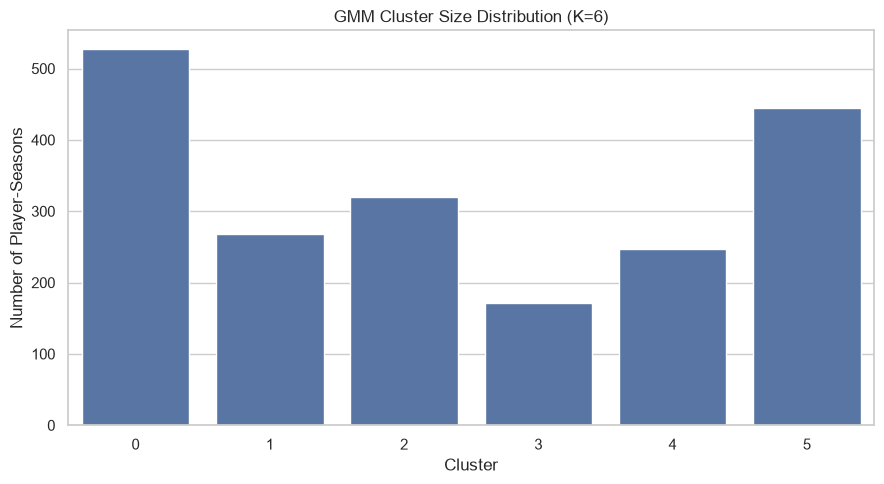

In [12]:

# 8.5 Cluster Size Analysis

cluster_sizes = pd.Series(
    cluster_labels
).value_counts().sort_index()

cluster_summary = pd.DataFrame({
    "Cluster": cluster_sizes.index,
    "Count": cluster_sizes.values,
    "Percentage": (
        cluster_sizes.values / len(X_array) * 100
    )
})

display(cluster_summary.round(2))

# Visualize cluster sizes

plt.figure(figsize=(9, 5))

sns.barplot(
    data=cluster_summary,
    x="Cluster",
    y="Count"
)

plt.title("GMM Cluster Size Distribution (K=6)")
plt.xlabel("Cluster")
plt.ylabel("Number of Player-Seasons")

plt.tight_layout()
plt.show()


Posterior Probability Summary
--------------------------------
Mean: 0.9434
Median: 0.9976
Minimum: 0.4129


,Confidence,Count,Percentage
0,High (>= 0.80),1762,89.03
1,Medium (0.60 - 0.80),137,6.92
2,Low (< 0.60),80,4.04


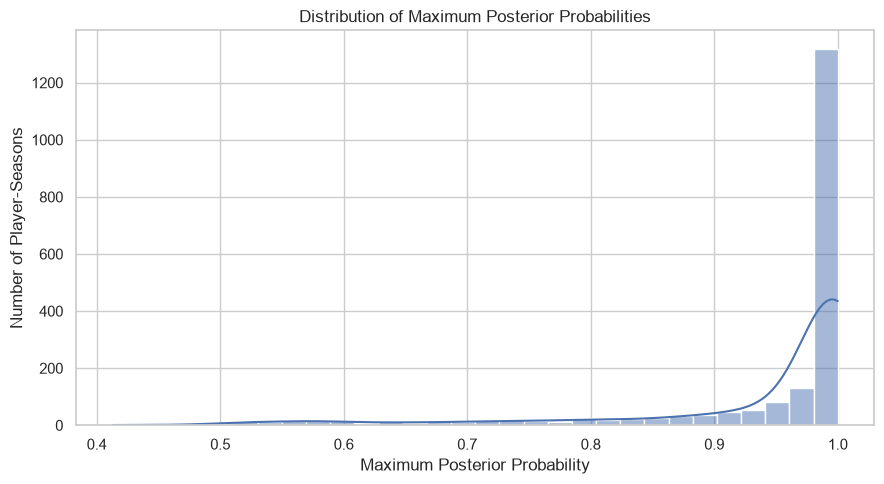

In [13]:

# 8.6 Posterior Probability Analysis

# Maximum posterior probability for each observation
max_prob = posterior_probs.max(axis=1)

print("Posterior Probability Summary")
print("--------------------------------")
print("Mean:", round(max_prob.mean(), 4))
print("Median:", round(np.median(max_prob), 4))
print("Minimum:", round(max_prob.min(), 4))

# Confidence categories
confidence_summary = pd.DataFrame({
    "Confidence": [
        "High (>= 0.80)",
        "Medium (0.60 - 0.80)",
        "Low (< 0.60)"
    ],
    "Count": [
        np.sum(max_prob >= 0.80),
        np.sum((max_prob >= 0.60) & (max_prob < 0.80)),
        np.sum(max_prob < 0.60)
    ]
})

confidence_summary["Percentage"] = (
    confidence_summary["Count"] / len(max_prob) * 100
)

display(confidence_summary.round(2))

# Visualize maximum posterior probabilities
plt.figure(figsize=(9, 5))

sns.histplot(
    max_prob,
    bins=30,
    kde=True
)

plt.title("Distribution of Maximum Posterior Probabilities")
plt.xlabel("Maximum Posterior Probability")
plt.ylabel("Number of Player-Seasons")

plt.tight_layout()
plt.show()


### 9. Cluster Profiling

We examine the mean standardized feature values
for each cluster to identify distinct NBA player archetypes.

In [14]:

# 9.1 Calculate Cluster Feature Profiles

feature_cols = [
    "USG_PCT_player_advanced",
    "AST_PCT_player_advanced",
    "OREB_PCT_player_advanced",
    "DREB_PCT_player_advanced",
    "PCT_PTS_FT_player_scoring",
    "PCT_PTS_FB_player_scoring",
    "SHOT_SHARE_PAINT_NON_RA",
    "SHOT_SHARE_MID_RANGE",
    "SHOT_SHARE_CORNER_3",
    "SHOT_SHARE_ABOVE_BREAK_3",
    "PCT_LOOSE_BALLS_RECOVERED_DEF_hustle",
    "PCT_BOX_OUTS_DEF_hustle",
    "FREQ_defend_rim",
    "SCREEN_ASSISTS_PER36"
]

# Reconstruct the standardized feature DataFrame
profile_df = pd.DataFrame(
    X_array,
    columns=feature_cols
)

profile_df["Cluster"] = cluster_labels

# Calculate mean feature values for each cluster
cluster_profiles = (
    profile_df
    .groupby("Cluster")[feature_cols]
    .mean()
)

display(cluster_profiles.round(3))


,USG_PCT_player_advanced,AST_PCT_player_advanced,OREB_PCT_player_advanced,DREB_PCT_player_advanced,PCT_PTS_FT_player_scoring,PCT_PTS_FB_player_scoring,SHOT_SHARE_PAINT_NON_RA,SHOT_SHARE_MID_RANGE,SHOT_SHARE_CORNER_3,SHOT_SHARE_ABOVE_BREAK_3,PCT_LOOSE_BALLS_RECOVERED_DEF_hustle,PCT_BOX_OUTS_DEF_hustle,FREQ_defend_rim,SCREEN_ASSISTS_PER36
Cluster,,,,,,,,,,,,,,
0,0.177,0.451,-0.720,-0.702,-0.144,0.246,-0.057,0.373,0.040,0.447,0.345,0.983,-0.361,-0.596
1,-0.746,-0.752,-0.354,-0.493,-0.685,0.562,-0.874,-0.491,1.278,0.477,0.231,0.204,-0.325,-0.458
2,-0.495,-0.576,0.509,0.440,-0.078,-0.036,-0.291,-0.650,0.398,-0.190,-0.184,-0.735,0.354,0.244
3,-0.722,-0.698,2.161,1.343,0.441,-1.010,0.669,-0.814,-1.272,-1.748,-0.620,-1.405,0.965,2.185
4,0.683,0.389,0.676,1.105,0.646,-0.694,0.785,0.243,-0.809,-0.562,-0.499,-0.633,0.513,0.935
5,0.496,0.387,-0.510,-0.321,0.110,0.172,0.110,0.501,-0.163,0.308,0.102,0.136,-0.288,-0.557


### 9.2 Cluster Feature Heatmap

The heatmap visualizes the mean standardized
feature values across the six GMM clusters.

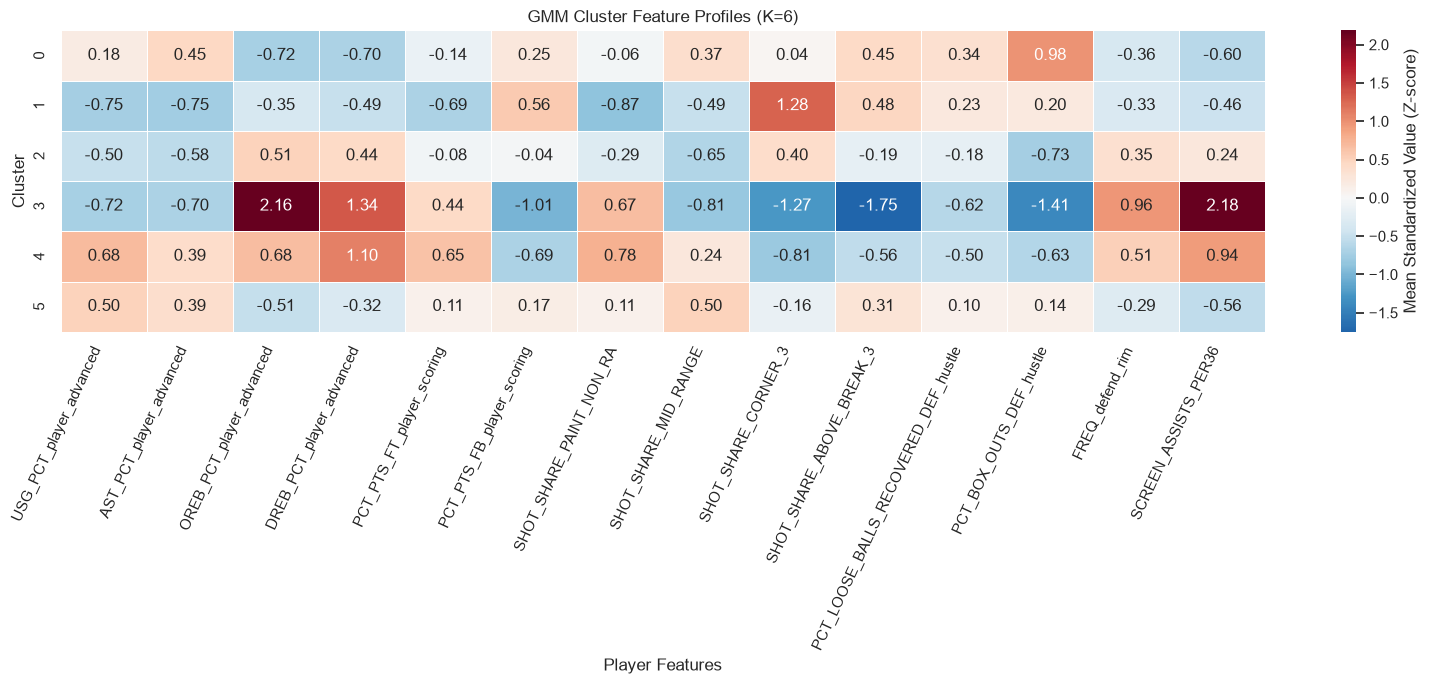

In [15]:

# 9.2 Visualize Cluster Profiles

plt.figure(figsize=(16, 7))

sns.heatmap(
    cluster_profiles,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Mean Standardized Value (Z-score)"}
)

plt.title("GMM Cluster Feature Profiles (K=6)")
plt.xlabel("Player Features")
plt.ylabel("Cluster")

plt.xticks(rotation=65, ha="right")
plt.tight_layout()
plt.show()


In [16]:

# 9.3 Identify Distinctive Features

for cluster in cluster_profiles.index:

    profile = cluster_profiles.loc[cluster]

    top_features = profile.sort_values(
        ascending=False
    )

    print(f"\n{'='*60}")
    print(f"Cluster {cluster}")
    print("="*60)

    print("\nTop 5 Positive Features:")
    print(top_features.head(5).round(3))

    print("\nTop 5 Negative Features:")
    print(top_features.tail(5).round(3))



Cluster 0

Top 5 Positive Features:
PCT_BOX_OUTS_DEF_hustle                 0.983
AST_PCT_player_advanced                 0.451
SHOT_SHARE_ABOVE_BREAK_3                0.447
SHOT_SHARE_MID_RANGE                    0.373
PCT_LOOSE_BALLS_RECOVERED_DEF_hustle    0.345
Name: 0, dtype: float64

Top 5 Negative Features:
PCT_PTS_FT_player_scoring   -0.144
FREQ_defend_rim             -0.361
SCREEN_ASSISTS_PER36        -0.596
DREB_PCT_player_advanced    -0.702
OREB_PCT_player_advanced    -0.720
Name: 0, dtype: float64

Cluster 1

Top 5 Positive Features:
SHOT_SHARE_CORNER_3                     1.278
PCT_PTS_FB_player_scoring               0.562
SHOT_SHARE_ABOVE_BREAK_3                0.477
PCT_LOOSE_BALLS_RECOVERED_DEF_hustle    0.231
PCT_BOX_OUTS_DEF_hustle                 0.204
Name: 1, dtype: float64

Top 5 Negative Features:
DREB_PCT_player_advanced    -0.493
PCT_PTS_FT_player_scoring   -0.685
USG_PCT_player_advanced     -0.746
AST_PCT_player_advanced     -0.752
SHOT_SHARE_PAINT_NON_RA    

Feature interpretation
|Cluster| Archetype|
| --- | --- |
|0|	Box-Out-Oriented Playmakers|
|1|	Low-Usage Corner 3 Specialists|
|2|	Rebounding-Oriented Bigs|
|3|	Screen-Setting Interior Bigs|
|4|	High-Usage Scoring Forwards|
|5|	Versatile Perimeter Scorers|

### 10. Representative Players for Each Cluster

Identify representative player-seasons based on
their Euclidean distance from their cluster centroid.

In [18]:

# 10.1 Load the standardized dataset

data = pd.read_csv(
    "../data/processed/clustering_features_standardized.csv"
)

# Verify that observations are aligned
assert len(data) == len(cluster_labels)

# Attach cluster labels
data["Cluster"] = cluster_labels

# Calculate maximum posterior probabilities
posterior_probs = gmm.predict_proba(X_array)

data["Confidence"] = posterior_probs.max(axis=1)

# Calculate representative players for each cluster
representative_players = []

for cluster in sorted(data["Cluster"].unique()):

    cluster_data = data[
        data["Cluster"] == cluster
    ].copy()

    # Calculate distance from cluster centroid
    centroid = cluster_profiles.loc[cluster].values

    cluster_data["Distance"] = np.linalg.norm(
        cluster_data[feature_cols].values - centroid,
        axis=1
    )

    # Select 10 most representative player-seasons
    top_players = cluster_data.nsmallest(
        10, "Distance"
    )

    representative_players.append(top_players)

# Combine results
representative_players = pd.concat(
    representative_players,
    ignore_index=True
)

# Display important information
display(
    representative_players[
        [
            "Cluster",
            "PLAYER_NAME",
            "SEASON",
            "TEAM_ABBREVIATION",
            "Distance",
            "Confidence"
        ]
    ].round(3)
)


,Cluster,PLAYER_NAME,SEASON,TEAM_ABBREVIATION,Distance,Confidence
0,0,Malachi Flynn,2023-24,DET,1.126,0.657
1,0,Coby White,2023-24,CHI,1.215,0.862
2,0,Caris LeVert,2022-23,CLE,1.239,0.383
3,0,Nickeil Alexander-Walker,2022-23,MIN,1.255,0.976
4,0,Immanuel Quickley,2022-23,NYK,1.279,0.585
5,0,Reggie Jackson,2022-23,DEN,1.316,0.894
6,0,Jaden Hardy,2024-25,DAL,1.346,0.660
7,0,Furkan Korkmaz,2021-22,PHI,1.395,0.946
8,0,Jaylen Nowell,2021-22,MIN,1.417,0.616
9,0,Evan Fournier,2023-24,DET,1.446,0.994
